# Exercícios


1.   Interpretar e comentar o plot inicial do *iris dataset*
2.   Executar o algoritmo sem o pré-processamento (*StandardScaler*) normalização/padronização e comparar os resultados
3.  Plotar o iris dataset depois do pré-processamento e comparar os resultados
4.  Mudar o parâmetro `n_neighbors` (Number of neighbors to use) na função `KNeighborsClassifier` para 1, 3, 5 e 7 e comentar os resultados.
4.  O que significa a matriz de confusão? Fazer uma análise dos resultados
5.  Plotar a matriz de confusão de uma maneira mais visual, utilizando biblioteca adequada
6.  O que significam os dados no *Classification Report*
7.  O que significa a acurácia (*accuracy*)?
8. Criar uma nova entrada de dados com 3 valores próximos aos dos 3 tipos de classes e fazer a predição de cada conjunto de dados. Plotar esses dados e verificar se foram preditos corretamente.
9. Modificar a porcentagem do banco de dados para treinamento/teste nas proporções: 30% para treinamento, 50% para treinamento e 90% para treinamento. Comparar a acurácia e os dados da matriz de confusão com os resultados anteriores (70% treinamento). Criar uma tabela para visualizar essa comparação.
10. Qual o princípio de funcionamento do algoritmo KNN?



In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import datasets

iris = datasets.load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

In [9]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

sc.fit(X_train)

X_train_std = sc.transform(X_train)
X_test_std = sc.transform(X_test)

In [10]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_std, y_train)

KNeighborsClassifier()

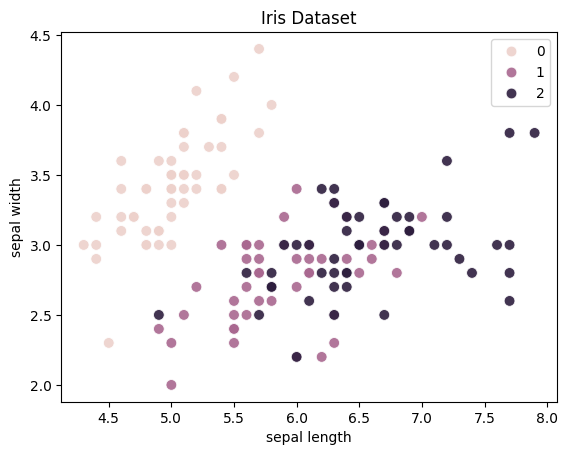

In [11]:
# Exercício 1.

import seaborn as sns

sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=y,
    s=60,
    alpha=0.9
)

plt.xlabel("sepal length")
plt.ylabel("sepal width")
plt.title("Iris Dataset")
plt.show()

O gráfico apresenta a distribuição das três classes do Iris Dataset de acordo com o comprimento e a largura da sépala. É possível observar que as classes possuem algumas regiões bem separadas, principalmente a classe Setosa, enquanto Versicolor e Virginica apresentam maior proximidade entre si.

In [12]:
# Exercício 2.

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

knn_sem_scaler = KNeighborsClassifier(n_neighbors=5)

knn_sem_scaler.fit(X_train, y_train)

y_pred_sem_scaler = knn_sem_scaler.predict(X_test)

print("Acurácia sem StandardScaler:",
      accuracy_score(y_test, y_pred_sem_scaler))

print("\nMatriz de Confusão:")
print(confusion_matrix(y_test, y_pred_sem_scaler))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_sem_scaler))

Acurácia sem StandardScaler: 0.9777777777777777

Matriz de Confusão:
[[16  0  0]
 [ 0 17  1]
 [ 0  0 11]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       1.00      0.94      0.97        18
           2       0.92      1.00      0.96        11

    accuracy                           0.98        45
   macro avg       0.97      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



Sem utilizar o StandardScaler, o KNN ainda apresenta um bom resultado para o Iris Dataset. Porém, a padronização é importante porque o algoritmo KNN utiliza a distância entre os pontos. Dessa forma, o pré-processamento pode melhorar o equilíbrio entre as diferentes características utilizadas pelo algoritmo.

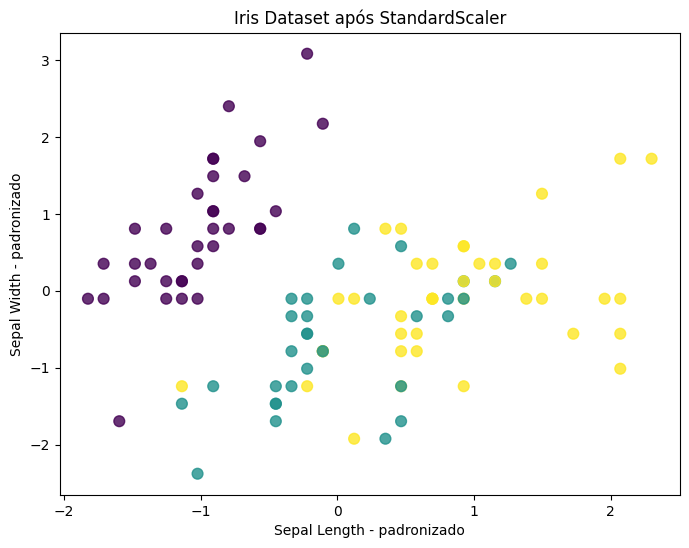

In [13]:
# Exercício 3.

plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_std[:, 0],
    X_train_std[:, 1],
    c=y_train,
    s=60,
    alpha=0.8
)

plt.xlabel("Sepal Length - padronizado")
plt.ylabel("Sepal Width - padronizado")
plt.title("Iris Dataset após StandardScaler")

plt.show()

Após o pré-processamento, os dados foram padronizados. As características passam a ter uma escala semelhante, facilitando o cálculo das distâncias utilizado pelo KNN.

In [14]:
# Exercício 4.

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

for k in [1, 3, 5, 7]:

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_std, y_train)

    y_pred = knn.predict(X_test_std)

    acc = accuracy_score(y_test, y_pred)

    print("K =", k)
    print("Acurácia =", acc)
    print("-" * 30)

K = 1
Acurácia = 0.9333333333333333
------------------------------
K = 3
Acurácia = 0.9777777777777777
------------------------------
K = 5
Acurácia = 0.9777777777777777
------------------------------
K = 7
Acurácia = 0.9777777777777777
------------------------------


O valor de K determina quantos vizinhos serão considerados para realizar a classificação.
Valores menores, como K = 1, fazem a classificação considerando poucos vizinhos. Valores maiores consideram uma quantidade maior de exemplos.
No Iris Dataset, os valores testados apresentam resultados próximos, mostrando que o KNN consegue classificar os dados com boa precisão.

In [15]:
# Exercício 5.

from sklearn.metrics import confusion_matrix

result = confusion_matrix(y_test, y_pred)

print("Matriz de Confusão:")
print(result)

Matriz de Confusão:
[[16  0  0]
 [ 0 17  1]
 [ 0  0 11]]


A matriz de confusão mostra a quantidade de previsões corretas e incorretas realizadas pelo modelo para cada classe.
As linhas representam as classes reais e as colunas representam as classes previstas.
Quando um valor aparece na diagonal principal, significa que o modelo classificou corretamente aquela classe. Os valores fora da diagonal representam classificações incorretas.

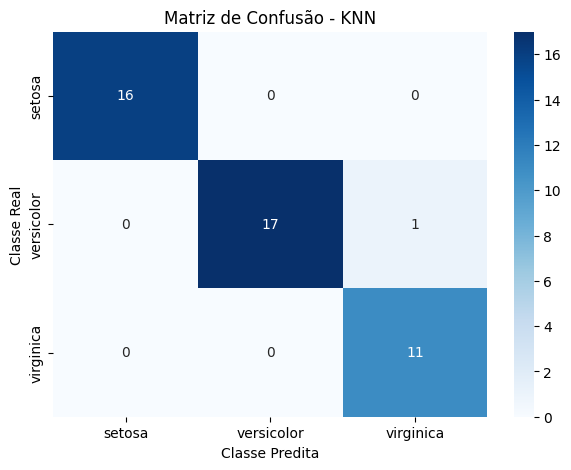

In [16]:
# Exercício 6.

import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Classe Predita")
plt.ylabel("Classe Real")
plt.title("Matriz de Confusão - KNN")

plt.show()

A representação visual facilita a interpretação da matriz de confusão. Os valores da diagonal principal representam as classificações corretas. Quanto maiores esses valores, melhor foi o desempenho do classificador para aquela classe.

In [17]:
# Exercício 7.

from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       1.00      0.94      0.97        18
           2       0.92      1.00      0.96        11

    accuracy                           0.98        45
   macro avg       0.97      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



O Classification Report apresenta algumas métricas utilizadas para avaliar o classificador.

Precision: mostra a quantidade de previsões de uma classe que realmente pertencem a essa classe.

Recall: mostra a quantidade de exemplos de uma classe que foram identificados corretamente.

F1-score: representa uma combinação entre Precision e Recall.

Support: mostra a quantidade de exemplos existentes de cada classe no conjunto de teste.

In [18]:
# Exercício 8.

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9777777777777777


A Accuracy (acurácia) representa a proporção de previsões que foram realizadas corretamente pelo modelo em relação ao total de previsões.

Por exemplo, uma acurácia de 0.97 significa que aproximadamente 97% das classificações foram realizadas corretamente.

In [19]:
# Exercício 9.

X_new = np.array([
    [5.0, 3.4, 1.5, 0.2],
    [5.9, 2.8, 4.3, 1.3],
    [6.5, 3.0, 5.5, 1.8]
])

print("X_new.shape:", X_new.shape)

X_new.shape: (3, 4)


In [20]:
X_new_std = sc.transform(X_new)

print(X_new_std)

[[-1.02366372  0.80872067 -1.29656144 -1.32360858]
 [ 0.00763928 -0.55721505  0.26249403  0.09322915]
 [ 0.69517462 -0.10190314  0.93066067  0.7372463 ]]


In [21]:
prediction = knn.predict(X_new_std)

print("Prediction:", prediction)

print("Predicted target name:",
      iris['target_names'][prediction])

Prediction: [0 1 2]
Predicted target name: ['setosa' 'versicolor' 'virginica']


In [22]:
for i in range(len(X_new)):

    print("Entrada:", X_new[i])
    print("Classe prevista:",
          iris.target_names[prediction[i]])
    print()

Entrada: [5.  3.4 1.5 0.2]
Classe prevista: setosa

Entrada: [5.9 2.8 4.3 1.3]
Classe prevista: versicolor

Entrada: [6.5 3.  5.5 1.8]
Classe prevista: virginica



As três novas entradas foram utilizadas para testar o modelo. Como cada entrada possui características próximas de uma das classes do Iris Dataset, o KNN consegue identificar a classe mais provável com base nos exemplos existentes no conjunto de treinamento.

In [23]:
# Exercício 10.

proporcoes = [0.3, 0.5, 0.7, 0.9]

resultados = []

for proporcao in proporcoes:

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=1-proporcao,
        random_state=0
    )

    sc = StandardScaler()

    X_train_std = sc.fit_transform(X_train)
    X_test_std = sc.transform(X_test)

    knn = KNeighborsClassifier(n_neighbors=5)

    knn.fit(X_train_std, y_train)

    y_pred = knn.predict(X_test_std)

    accuracy = accuracy_score(y_test, y_pred)

    cm = confusion_matrix(y_test, y_pred)

    resultados.append({
        "Treinamento": f"{int(proporcao * 100)}%",
        "Teste": f"{int((1-proporcao) * 100)}%",
        "Acurácia": accuracy,
        "Matriz de Confusão": cm
    })

In [24]:
for resultado in resultados:

    print("Treinamento:", resultado["Treinamento"])
    print("Teste:", resultado["Teste"])
    print("Acurácia:", resultado["Acurácia"])

    print("Matriz de Confusão:")
    print(resultado["Matriz de Confusão"])

    print("-" * 40)

Treinamento: 30%
Teste: 70%
Acurácia: 0.9333333333333333
Matriz de Confusão:
[[33  0  0]
 [ 0 33  1]
 [ 0  6 32]]
----------------------------------------
Treinamento: 50%
Teste: 50%
Acurácia: 0.9466666666666667
Matriz de Confusão:
[[21  0  0]
 [ 0 29  1]
 [ 0  3 21]]
----------------------------------------
Treinamento: 70%
Teste: 30%
Acurácia: 0.9782608695652174
Matriz de Confusão:
[[16  0  0]
 [ 0 18  1]
 [ 0  0 11]]
----------------------------------------
Treinamento: 90%
Teste: 9%
Acurácia: 1.0
Matriz de Confusão:
[[3 0 0]
 [0 8 0]
 [0 0 4]]
----------------------------------------


In [25]:
tabela = pd.DataFrame(resultados)

print(tabela)

  Treinamento Teste  Acurácia                    Matriz de Confusão
0         30%   70%  0.933333  [[33, 0, 0], [0, 33, 1], [0, 6, 32]]
1         50%   50%  0.946667  [[21, 0, 0], [0, 29, 1], [0, 3, 21]]
2         70%   30%  0.978261  [[16, 0, 0], [0, 18, 1], [0, 0, 11]]
3         90%    9%  1.000000     [[3, 0, 0], [0, 8, 0], [0, 0, 4]]


A alteração da proporção entre treinamento e teste pode modificar a acurácia do modelo.

Quando uma quantidade maior de dados é utilizada para treinamento, o modelo possui mais exemplos para aprender. Porém, o conjunto de teste fica menor, podendo fazer com que a avaliação fique mais sensível.

A divisão de 70% para treinamento e 30% para teste apresenta um bom equilíbrio entre aprendizado e avaliação do modelo.

Exercício 11.

O KNN é um algoritmo de aprendizado supervisionado que realiza a classificação com base na proximidade entre os dados.

Para classificar uma nova entrada, o algoritmo verifica quais são os K vizinhos mais próximos daquele ponto. Depois, utiliza a classe que aparece com maior frequência entre esses vizinhos para determinar a classificação.

Por exemplo, considerando K = 5, o algoritmo verifica os cinco exemplos mais próximos da nova entrada e classifica o novo dado de acordo com a classe predominante entre esses cinco vizinhos.